In [22]:
import tensorflow as tf
from tensorflow.keras import layers, models 
import matplotlib.pyplot as plt

In [23]:
dataset=tf.keras.preprocessing.image_dataset_from_directory(
   "potato_images",
    image_size=(256,256),
    batch_size=32,
    shuffle=True,
)

Found 2152 files belonging to 3 classes.


In [24]:
class_names=dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [25]:
len(dataset)

68

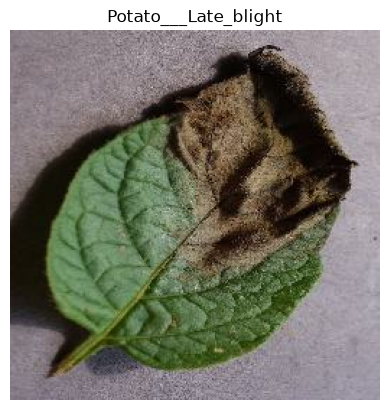

In [26]:
for image,label in dataset.take(1):
    # print(image)
    # print(label)
    plt.imshow(image[0].numpy().astype('uint8'))
    plt.title(class_names[label[0]])
    plt.axis('off')
    plt.show()

In [27]:
train_size=len(dataset)*0.8
train_dataset=dataset.take(int(train_size))
len(train_dataset)


54

In [28]:
test_ds=dataset.skip(int(train_size))
len(test_ds)

14

In [29]:
val_size=0.1
len(dataset)*val_size

6.800000000000001

In [30]:
val_ds=test_ds.take(6)

In [31]:
def get_dataset_partitions(
    ds,
    train_split=0.8,
    val_split=0.1,
    test_split=0.1,
    shuffle=True,
    shuffle_size=10000
):
    if shuffle:
        ds = ds.shuffle(buffer_size=shuffle_size, seed=12)

    dataset_size = len(ds)

    train_size = int(train_split * dataset_size)
    val_size = int(val_split * dataset_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)

    return train_ds, val_ds, test_ds

In [32]:
train_ds,val_ds,test_ds=get_dataset_partitions(dataset)

In [33]:
len(train_ds),len(val_ds),len(test_ds)

(54, 6, 8)

In [34]:
train_ds=train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds=val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds=test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [35]:
rescaling_layer=tf.keras.Sequential([
    layers.Resizing(256,256),
    layers.Rescaling(1./255)])

In [36]:
data_augmentation=tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2)
])

In [37]:
model=models.Sequential([
    rescaling_layer,
    data_augmentation,
    layers.Conv2D(16,3,input_shape=(256,256,3),activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3,input_shape=(256,256,3),activation='relu'),
    layers.MaxPooling2D(),  
    layers.Conv2D(64,3,input_shape=(256,256,3),activation='relu'),  
    layers.MaxPooling2D(),
    
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(len(class_names),activation='softmax')
    ])
model.build(input_shape=(None,256,256,3))

In [38]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,396,899 (28.22 MB)

 Trainable params: 7,396,899 (28.22 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])


In [40]:
history=model.fit(train_ds,
          validation_data=val_ds,
          epochs=50,
          batch_size=32)

Epoch 1/50


/home/manoj/tensorflow-gpu/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793458479.464653   26394 cuda_dnn.cc:461] Loaded cuDNN version 92501


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.7483 - loss: 0.8646

I0000 00:00:1793458506.327744   26861 shuffle_dataset_op.cc:453] ShuffleDatasetV3:43: Filling up shuffle buffer (this may take a while): 26 of 10000
I0000 00:00:1793458507.073357   26861 shuffle_dataset_op.cc:483] Shuffle buffer filled.
I0000 00:00:1793458507.077224   26861 shuffle_dataset_op.cc:483] Shuffle buffer filled.
W0000 00:00:1793458507.077543   26860 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 25166080 bytes after encountering the first element of size 25166080 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


54/54 ━━━━━━━━━━━━━━━━━━━━ 39s 414ms/step - accuracy: 0.7483 - loss: 0.8646 - val_accuracy: 0.8594 - val_loss: 0.4743
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.9016 - loss: 0.2716 - val_accuracy: 0.9479 - val_loss: 0.1512
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 105ms/step - accuracy: 0.9271 - loss: 0.1997 - val_accuracy: 0.8698 - val_loss: 0.3448
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - accuracy: 0.9508 - loss: 0.1361 - val_accuracy: 0.8958 - val_loss: 0.2228
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.9554 - loss: 0.1267 - val_accuracy: 0.9062 - val_loss: 0.2486
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - accuracy: 0.9265 - loss: 0.1894 - val_accuracy: 0.8333 - val_loss: 0.5014
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.9525 - loss: 0.1219 - val_accuracy: 0.9323 - val_loss: 0.1396
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.9618 - loss: 0.0892

W0000 00:00:1793458547.630714   26860 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 41935872 bytes after encountering the first element of size 41935872 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 148ms/step - accuracy: 0.9618 - loss: 0.0892 - val_accuracy: 0.9271 - val_loss: 0.1570
Epoch 9/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - accuracy: 0.9705 - loss: 0.0848 - val_accuracy: 0.9115 - val_loss: 0.2764
Epoch 10/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.9473 - loss: 0.1302 - val_accuracy: 0.9219 - val_loss: 0.1562
Epoch 11/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.9682 - loss: 0.0910 - val_accuracy: 0.9062 - val_loss: 0.3112
Epoch 12/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.9711 - loss: 0.0763 - val_accuracy: 0.9271 - val_loss: 0.2045
Epoch 13/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9525 - loss: 0.1320 - val_accuracy: 0.9115 - val_loss: 0.1794
Epoch 14/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9688 - loss: 0.0759 - val_accuracy: 0.9479 - val_loss: 0.1015
Epoch 15/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.9641 - loss: 0.0952 - val_accuracy: 0.9479 - val_

In [41]:
model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9805 - loss: 0.0530


[0.052953168749809265, 0.98046875]

In [42]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

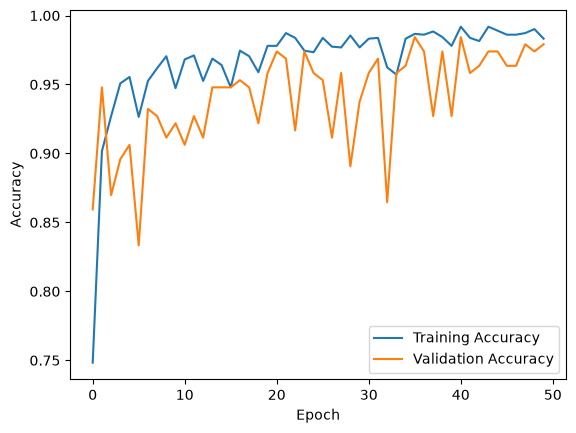

In [43]:

acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
loss=history.history['loss']
val_loss=history.history['val_loss']
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

first image
first label: Potato___Early_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 571ms/step
prediction: Potato___Early_blight


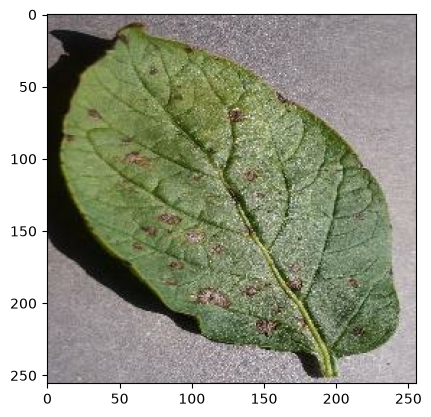

In [44]:
#each batch contains 32 images and labels
import numpy as np

for image,batch in test_ds.take(1):
    first_image = image[31].numpy().astype('uint8')
    first_label = batch[31].numpy()
    plt.imshow(first_image)
    print("first image")
    print("first label:", class_names[first_label])
    prediction = model.predict(image)
    print("prediction:", class_names[np.argmax(prediction[31])])


In [45]:
def predict(model,img):
    img_array=tf.keras.preprocessing.image.img_to_array(img)
    img_array=tf.expand_dims(img_array,0)
    prediction=model.predict(img_array)
    confidence=round(100*(np.argmax(prediction[0])),2)
    return prediction, confidence

W0000 00:00:1793458974.607352   26008 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 25166080 bytes after encountering the first element of size 25166080 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


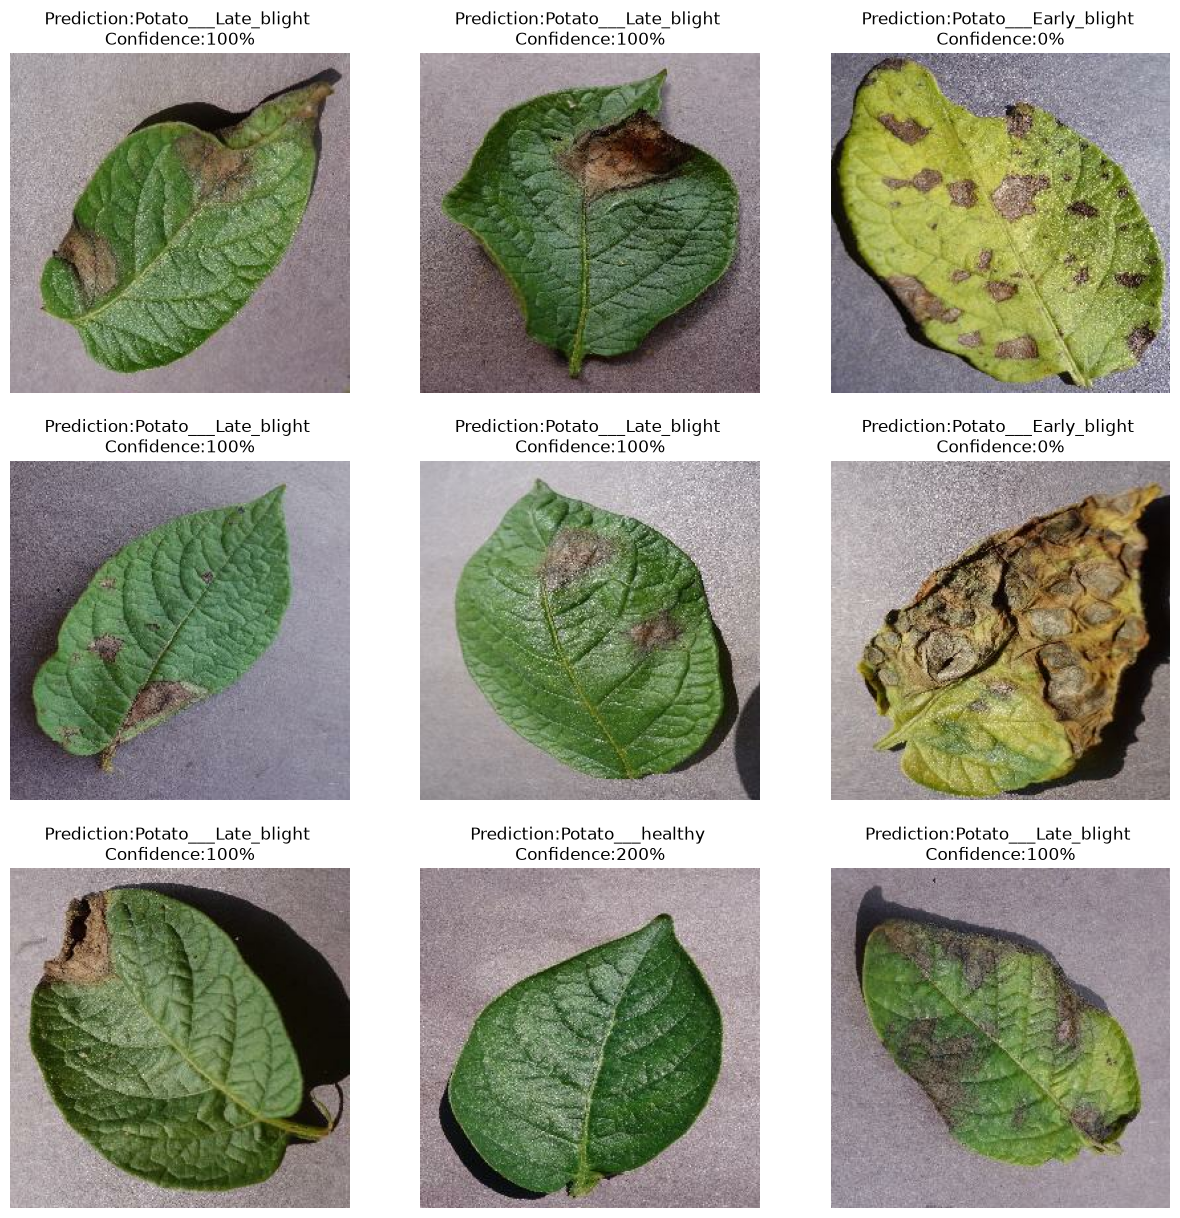

In [50]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,15))
for image,label in test_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype('uint8'))
        prediction,confidence=predict(model,image[i])
        actual_label=class_names[label[i]]
        plt.title(f"Prediction:{class_names[np.argmax(prediction[0])]} \nConfidence:{confidence}%")
        plt.axis('off')

In [51]:
model_version=1
model.save(f"potato_model_v{model_version}.h5")

In [53]:

import os

print(os.path.exists("potato_model_v1.h5"))

True
